# PUNTO 3

# Sistemas de amortización

In [24]:
import pandas as pd 
import numpy as np

In [25]:
datos= pd.read_excel("datos/datos_limpio_automovil.xlsx")

In [26]:
datos.head()

,Unnamed: 0,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,...,Estudios_Escolar,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Estado_Civil_Casado,Estado_Civil_Divorciado,Estado_Civil_Soltero
0,0,O77MPJ,26,19153,6973,706,9,1,19.05,36,...,False,True,False,False,False,True,False,False,False,True
1,8,IYOL1S,29,39531,40000,826,0,1,9.74,24,...,False,False,False,False,False,True,False,True,False,False
2,9,FRMZVN,29,40348,16448,740,9,1,14.73,24,...,False,False,True,False,False,True,False,False,False,True
3,26,YKHXVY,38,41732,42040,661,173,2,13.24,48,...,False,True,False,False,False,False,True,True,False,False
4,32,NHDJTK,35,35085,16406,759,181,1,9.74,36,...,True,False,False,False,False,True,False,True,False,False


In [27]:
datos.columns


Index(['Unnamed: 0', 'ID', 'Edad', 'Ingresos', 'Monto_Inicial',
       'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes',
       'Duracion', 'Ratio_Deuda_Ingresos', 'Posesion_Hipoteca',
       'Personas_Cargo', 'Fiador', 'Impago', 'Prima', 'Estudios_Doctorado',
       'Estudios_Escolar', 'Estudios_Grado Universitario', 'Estudios_Máster',
       'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial', 'Estado_Civil_Casado',
       'Estado_Civil_Divorciado', 'Estado_Civil_Soltero'],
      dtype='str')

In [28]:
datos.shape

(76924, 27)

In [29]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 76924 entries, 0 to 76923
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Unnamed: 0                             76924 non-null  int64  
 1   ID                                     76924 non-null  str    
 2   Edad                                   76924 non-null  int64  
 3   Ingresos                               76924 non-null  int64  
 4   Monto_Inicial                          76924 non-null  int64  
 5   Scoring_Crediticio                     76924 non-null  int64  
 6   Meses_Empleo                           76924 non-null  int64  
 7   Num_Creditos                           76924 non-null  int64  
 8   Ratio_Interes                          76924 non-null  float64
 9   Duracion                               76924 non-null  int64  
 10  Ratio_Deuda_Ingresos                   76924 non-null  float64
 11  Posesion_Hipo

# 1- Cuadros de amortización 

Cambiamos los nombres para hacer mas facil la formula 
- Monto inicial-->capital_prestado
- Ratio Interes -->  interés_anual.
- Duración --> num_meses

In [30]:
datos = datos.rename(columns={
    "Monto_Inicial": "capital_prestado",
    "Ratio_Interes": "interes_anual",
    "Duracion": "num_meses"
})
print(datos.info())

<class 'pandas.DataFrame'>
RangeIndex: 76924 entries, 0 to 76923
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Unnamed: 0                             76924 non-null  int64  
 1   ID                                     76924 non-null  str    
 2   Edad                                   76924 non-null  int64  
 3   Ingresos                               76924 non-null  int64  
 4   capital_prestado                       76924 non-null  int64  
 5   Scoring_Crediticio                     76924 non-null  int64  
 6   Meses_Empleo                           76924 non-null  int64  
 7   Num_Creditos                           76924 non-null  int64  
 8   interes_anual                          76924 non-null  float64
 9   num_meses                              76924 non-null  int64  
 10  Ratio_Deuda_Ingresos                   76924 non-null  float64
 11  Posesion_Hipo

In [31]:
columnas_necesarias = [
    "ID", "capital_prestado", "interes_anual",
    "num_meses", "Ingresos"
]

faltantes = [c for c in columnas_necesarias if c not in datos.columns]
if faltantes:
    raise ValueError(
        f"Faltan columnas necesarias en el Excel: {faltantes}"
    )

if datos["ID"].isna().any() or datos["ID"].duplicated().any():
    raise ValueError("Los ID deben existir y ser únicos.")

for col in ["capital_prestado", "interes_anual",
            "num_meses", "Ingresos"]:
    datos[col] = pd.to_numeric(datos[col], errors="raise")

if datos[columnas_necesarias[1:]].isna().any().any():
    raise ValueError("Hay valores vacíos en las variables financieras.")

if (datos["capital_prestado"] <= 0).any():
    raise ValueError("El capital prestado debe ser positivo.")

if (datos["interes_anual"] < 0).any():
    raise ValueError("El interés anual no puede ser negativo.")

if ((datos["num_meses"] <= 0) |
    (datos["num_meses"] % 1 != 0)).any():
    raise ValueError("La duración debe ser un número entero de meses.")

if (datos["Ingresos"] <= 0).any():
    raise ValueError("Los ingresos deben ser positivos.")

datos["num_meses"] = datos["num_meses"].astype(int)

In [32]:
UMBRAL_CARGA = 0.30

Parámetro de decisión del método (hipótesis propia, no figura en el temario)
Un préstamo se asigna al sistema ALEMÁN solo si su primera cuota (la más alta)
no supera este porcentaje del ingreso mensual (Ingresos / 12, Ingresos anuales).
Si no, se queda con el FRANCÉS (cuota constante y menor al inicio).  Poner UMBRAL_CARGA = None para elegir solo por mínimo de intereses (todos alemán).

# Sistema Francés

La cuota es constante.
Los intereses disminuyen.
La amortización de capital aumenta.

Crear la función del sistema francés

In [33]:
def cuadro_frances(capital, interes_anual, meses):

    i = interes_anual / 100 / 12
    cuota = (
        capital / meses
        if i == 0
        else capital * i / (1 - (1 + i) ** (-meses))
    )

    saldo = float(capital)
    tabla = []

    for periodo in range(1, meses + 1):
        intereses = saldo * i
        capital_amortizado = cuota - intereses

        # Evita un saldo residual por precisión numérica
        if periodo == meses:
            capital_amortizado = saldo
            cuota_periodo = capital_amortizado + intereses
        else:
            cuota_periodo = cuota

        saldo = max(0.0, saldo - capital_amortizado)

        tabla.append([
            periodo, cuota_periodo, intereses,
            capital_amortizado, saldo
        ])

    return pd.DataFrame(tabla, columns=[
        "Periodo", "Cuota", "Intereses",
        "Capital_Amortizado", "Saldo_Pendiente"
    ])

# Sistema Alemán

La amortización es constante.

Funcion del sistema alemán

In [34]:
def cuadro_aleman(capital, interes_anual, meses):

    i = interes_anual / 100 / 12
    amortizacion = capital / meses
    saldo = float(capital)
    tabla = []

    for periodo in range(1, meses + 1):
        intereses = saldo * i
        capital_amortizado = (
            saldo if periodo == meses else amortizacion
        )
        cuota = capital_amortizado + intereses

        saldo = max(0.0, saldo - capital_amortizado)

        tabla.append([
            periodo, cuota, intereses,
            capital_amortizado, saldo
        ])

    return pd.DataFrame(tabla, columns=[
        "Periodo", "Cuota", "Intereses",
        "Capital_Amortizado", "Saldo_Pendiente"
    ])


Cuadro completo para todos los prestamos

In [35]:
cuadros_frances = {}
cuadros_aleman = {}

for _, fila in datos.iterrows():
    id_prestamo = fila["ID"]
    capital = float(fila["capital_prestado"])
    interes = float(fila["interes_anual"])
    meses = int(fila["num_meses"])

    cuadros_frances[id_prestamo] = cuadro_frances(
        capital, interes, meses
    )
    cuadros_aleman[id_prestamo] = cuadro_aleman(
        capital, interes, meses
    )

Mostrar los cuadros del primer préstamo

In [36]:
id_ejemplo = datos.iloc[0]["ID"]

print("CUADRO FRANCÉS")
display(cuadros_frances[id_ejemplo].round(2))

print("CUADRO ALEMÁN")
display(cuadros_aleman[id_ejemplo].round(2))

CUADRO FRANCÉS


,Periodo,Cuota,Intereses,Capital_Amortizado,Saldo_Pendiente
0,1,255.78,110.70,145.08,6827.92
1,2,255.78,108.39,147.39,6680.53
2,3,255.78,106.05,149.73,6530.81
3,4,255.78,103.68,152.10,6378.70
4,5,255.78,101.26,154.52,6224.19
5,6,255.78,98.81,156.97,6067.22
6,7,255.78,96.32,159.46,5907.76
7,8,255.78,93.79,161.99,5745.76
8,9,255.78,91.21,164.56,5581.20
9,10,255.78,88.60,167.18,5414.02


CUADRO ALEMÁN


,Periodo,Cuota,Intereses,Capital_Amortizado,Saldo_Pendiente
0,1,304.39,110.70,193.69,6779.31
1,2,301.32,107.62,193.69,6585.61
2,3,298.24,104.55,193.69,6391.92
3,4,295.17,101.47,193.69,6198.22
4,5,292.09,98.40,193.69,6004.53
5,6,289.02,95.32,193.69,5810.83
6,7,285.94,92.25,193.69,5617.14
7,8,282.87,89.17,193.69,5423.44
8,9,279.79,86.10,193.69,5229.75
9,10,276.72,83.02,193.69,5036.06


Comparar francés y alemán t elección del metodo

In [38]:
# Se recomienda el alemán solo si su primera cuota no supera
# el 30 % de los ingresos mensuales.
# En caso contrario, se elige el francés.
# La recomendación considera la capacidad de pago inicial,
# además del ahorro de intereses que proporciona el alemán.

filas_comparacion = []

for _, fila in datos.iterrows():
    id_prestamo = fila["ID"]
    ingreso_mensual = fila["Ingresos"] / 12

    fr = cuadros_frances[id_prestamo]
    al = cuadros_aleman[id_prestamo]

    cuota_frances = fr["Cuota"].iloc[0]
    cuota_aleman = al["Cuota"].iloc[0]

    intereses_frances = fr["Intereses"].sum()
    intereses_aleman = al["Intereses"].sum()

    esfuerzo_frances = cuota_frances / ingreso_mensual
    esfuerzo_aleman = cuota_aleman / ingreso_mensual

    if esfuerzo_aleman <= UMBRAL_CARGA:
        metodo = "Alemán"
    else:
        metodo = "Francés"

    filas_comparacion.append({
        "ID": id_prestamo,
        "Cuota_Inicial_Frances": cuota_frances,
        "Cuota_Inicial_Aleman": cuota_aleman,
        "Esfuerzo_Frances_%": esfuerzo_frances * 100,
        "Esfuerzo_Aleman_%": esfuerzo_aleman * 100,
        "Intereses_Frances": intereses_frances,
        "Intereses_Aleman": intereses_aleman,
        "Ahorro_Intereses_Aleman":
            intereses_frances - intereses_aleman,
        "Metodo_Recomendado": metodo
    })

comparacion = pd.DataFrame(filas_comparacion)

print("RESUMEN DE MÉTODOS RECOMENDADOS")
print(comparacion["Metodo_Recomendado"].value_counts())
print(
    (comparacion["Metodo_Recomendado"]
     .value_counts(normalize=True) * 100).round(2)
)

print(
    "\nAhorro medio de intereses si se usa el alemán:",
    round(comparacion["Ahorro_Intereses_Aleman"].mean(), 2),
    "€"
)

print(
    "Ahorro total potencial del alemán:",
    round(comparacion["Ahorro_Intereses_Aleman"].sum(), 2),
    "€"
)

print("\nEjemplos de comparación:")
display(comparacion.head(10).round(2))

RESUMEN DE MÉTODOS RECOMENDADOS
Metodo_Recomendado
Francés    43340
Alemán     33584
Name: count, dtype: int64
Metodo_Recomendado
Francés    56.34
Alemán     43.66
Name: proportion, dtype: float64

Ahorro medio de intereses si se usa el alemán: 523.02 €
Ahorro total potencial del alemán: 40233076.23 €

Ejemplos de comparación:


,ID,Cuota_Inicial_Frances,Cuota_Inicial_Aleman,Esfuerzo_Frances_%,Esfuerzo_Aleman_%,Intereses_Frances,Intereses_Aleman,Ahorro_Intereses_Aleman,Metodo_Recomendado
0,O77MPJ,255.78,304.39,16.03,19.07,2235.03,2047.88,187.15,Alemán
1,IYOL1S,1841.00,1991.33,55.89,60.45,4184.02,4058.33,125.68,Francés
2,FRMZVN,795.40,887.23,23.66,26.39,2641.60,2523.74,117.86,Alemán
3,YKHXVY,1132.84,1339.67,32.57,38.52,12336.42,11364.11,972.31,Francés
4,NHDJTK,527.38,588.88,18.04,20.14,2579.50,2463.50,116.01,Alemán
5,VIWISD,2624.93,2729.81,121.07,125.90,1534.19,1512.73,21.45,Francés
6,SA6S9R,314.14,347.65,7.46,8.26,1391.22,1334.84,56.38,Alemán
7,DCJ69B,407.82,433.85,9.23,9.82,1039.61,1015.82,23.79,Alemán
8,E5TVKC,288.24,317.34,7.55,8.32,824.84,793.36,31.48,Alemán
9,N7B3CO,10318.54,11508.57,206.79,230.64,34227.01,32701.86,1525.15,Francés


In [39]:
comparacion.head()

,ID,Cuota_Inicial_Frances,Cuota_Inicial_Aleman,Esfuerzo_Frances_%,Esfuerzo_Aleman_%,Intereses_Frances,Intereses_Aleman,Ahorro_Intereses_Aleman,Metodo_Recomendado
0,O77MPJ,255.778738,304.390819,16.025400,19.071111,2235.034579,2047.882938,187.151642,Alemán
1,IYOL1S,1841.000634,1991.333333,55.885274,60.448762,4184.015211,4058.333333,125.681878,Francés
2,FRMZVN,795.400039,887.232533,23.656192,26.387406,2641.600945,2523.740000,117.860945,Alemán
3,YKHXVY,1132.842089,1339.674667,32.574775,38.522228,12336.420285,11364.112667,972.307619,Francés
4,NHDJTK,527.375078,588.884256,18.037626,20.141402,2579.502794,2463.497617,116.005177,Alemán


In [40]:
# Recuento de préstamos por método recomendado
recuento = comparacion["Metodo_Recomendado"].value_counts()
porcentaje = comparacion["Metodo_Recomendado"].value_counts(normalize=True).mul(100).round(2)

resumen_metodos = pd.DataFrame({"Préstamos": recuento, "% de la cartera": porcentaje})
print(resumen_metodos)

# Ahorro medio de intereses del alemán frente al francés
ahorro = comparacion["Intereses_Frances"] - comparacion["Intereses_Aleman"]
print(f"\nAhorro medio de intereses con el alemán: {ahorro.mean():,.2f} €")
print(f"Ahorro total en la cartera: {ahorro.sum():,.2f} €")

                    Préstamos  % de la cartera
Metodo_Recomendado                            
Francés                 43340            56.34
Alemán                  33584            43.66

Ahorro medio de intereses con el alemán: 523.02 €
Ahorro total en la cartera: 40,233,076.23 €


# PUNTO 4

In [41]:
# Hipótesis: coste de oportunidad anual efectivo del banco = 4 %.
# Se transforma a una tasa mensual equivalente para descontar
# los flujos mensuales.
#
# VAN = -capital inicial + suma de cuotas descontadas.
# TIR = tasa que hace que el VAN sea igual a cero.
# La TIR anual se expresa como tasa efectiva anual.

K_ANUAL = 0.04

def tasa_mensual(k_anual):
    return (1 + k_anual) ** (1 / 12) - 1


def calcular_van(tasa_mensual, flujos):
    return sum(
        flujo / (1 + tasa_mensual) ** periodo
        for periodo, flujo in enumerate(flujos)
    )


def calcular_tir_mensual(flujos, iteraciones=150):
    """
    TIR mediante bisección para flujos convencionales:
    desembolso inicial negativo y cuotas posteriores positivas.
    """
    van_cero = calcular_van(0.0, flujos)

    if np.isclose(van_cero, 0.0, atol=1e-10):
        return 0.0

    if van_cero < 0:
        raise ValueError(
            "No se encuentra una TIR no negativa para estos flujos."
        )

    bajo = 0.0
    alto = 0.01

    while calcular_van(alto, flujos) > 0:
        alto *= 2
        if alto > 1e6:
            raise ValueError("No se pudo acotar la TIR.")

    for _ in range(iteraciones):
        medio = (bajo + alto) / 2

        if calcular_van(medio, flujos) > 0:
            bajo = medio
        else:
            alto = medio

    return (bajo + alto) / 2

Evaluar cada préstamo con el método recomendado

In [44]:
r = tasa_mensual(K_ANUAL)
metodos = comparacion.set_index("ID")["Metodo_Recomendado"]
resultados = []

for _, fila in datos.iterrows():
    id_prestamo = fila["ID"]
    capital = float(fila["capital_prestado"])

    metodo = metodos.loc[id_prestamo]

    if metodo == "Alemán":
        cuadro = cuadros_aleman[id_prestamo]
    else:
        cuadro = cuadros_frances[id_prestamo]

    flujos = [-capital] + cuadro["Cuota"].tolist()

    van = calcular_van(r, flujos)
    tir_m = calcular_tir_mensual(flujos)
    tir_anual = (1 + tir_m) ** 12 - 1

    resultados.append({
        "ID": id_prestamo,
        "Metodo": metodo,
        "Capital": capital,
        "VAN": van,
        "TIR_mensual_%": tir_m * 100,
        "TIR_anual_%": tir_anual * 100
    })

viabilidad = pd.DataFrame(resultados)

viabilidad["Decision"] = np.where(
    (viabilidad["VAN"] > 0) &
    (viabilidad["TIR_anual_%"] > K_ANUAL * 100),
    "Viable",
    "No viable"
)

print(f"Tasa de descuento anual: {K_ANUAL:.2%}")
print(f"Tasa mensual equivalente: {r:.6%}")
print(f"VAN total de la cartera: {viabilidad['VAN'].sum():,.2f} €")
print(f"VAN medio por préstamo: {viabilidad['VAN'].mean():,.2f} €")
print("\nDecisión de viabilidad:")
print(viabilidad["Decision"].value_counts())
print(
    "\nPorcentaje de préstamos viables:",
    f"{(viabilidad['Decision'] == 'Viable').mean():.2%}"
)

print("\nPrimeros resultados:")
display(viabilidad.head(10).round(2))


Tasa de descuento anual: 4.00%
Tasa mensual equivalente: 0.327374%
VAN total de la cartera: 372,544,896.19 €
VAN medio por préstamo: 4,843.03 €

Decisión de viabilidad:
Decision
Viable       74303
No viable     2621
Name: count, dtype: int64

Porcentaje de préstamos viables: 96.59%

Primeros resultados:


,ID,Metodo,Capital,VAN,TIR_mensual_%,TIR_anual_%,Decision
0,O77MPJ,Alemán,6973.0,1560.26,1.59,20.80,Viable
1,IYOL1S,Francés,40000.0,2426.11,0.81,10.19,Viable
2,FRMZVN,Alemán,16448.0,1799.29,1.23,15.77,Viable
3,YKHXVY,Francés,42040.0,8203.43,1.10,14.07,Viable
4,NHDJTK,Alemán,16406.0,1410.83,0.81,10.19,Viable
5,VIWISD,Francés,29965.0,874.02,0.78,9.73,Viable
6,SA6S9R,Alemán,9918.0,704.67,0.73,9.09,Viable
7,DCJ69B,Alemán,13642.0,181.98,0.40,4.94,Viable
8,E5TVKC,Alemán,6093.0,528.92,1.04,13.24,Viable
9,N7B3CO,Francés,213418.0,24374.24,1.23,15.74,Viable


In [48]:
import numpy as np
import pandas as pd
# import numpy_financial as npf   # opcional, para validar 

# ---------------------------------------------------------------
# SUPUESTO: k = tasa de descuento anual efectiva (rentabilidad mínima exigida).
# Debe justificarse en el trabajo (coste de financiación del banco, etc.).
# ---------------------------------------------------------------
K_ANUAL = 0.04

def tasa_mensual(k_anual):
    return (1 + k_anual) ** (1 / 12) - 1

# Método de cada préstamo (viene del Punto 3)
metodos = comparacion.set_index("ID")["Metodo_Recomendado"]

# 1) Flujos de caja del banco por grupos (mismo plazo y mismo método), SIN redondear
def construir_grupos(datos, metodos):
    d = datos[["ID", "capital_prestado", "interes_anual", "num_meses"]].copy()
    d["metodo"] = d["ID"].map(metodos)
    grupos = []
    for (n, met), g in d.groupby(["num_meses", "metodo"]):
        n = int(n)
        C = g["capital_prestado"].to_numpy(dtype=float)
        i = g["interes_anual"].to_numpy(dtype=float) / 100 / 12   # tipo mensual del préstamo
        t = np.arange(1, n + 1)                                    # meses 1..n
        if met == "Alemán":
            A = C / n                                              # amortización constante
            cuotas = A[:, None] + (C[:, None] - (t - 1)[None, :] * A[:, None]) * i[:, None]
        else:                                                      # Francés: cuota constante
            cuota = C * i / (1 - (1 + i) ** (-n))
            cuotas = np.repeat(cuota[:, None], n, axis=1)
        grupos.append((g["ID"].to_numpy(), met, C, t, cuotas))
    return grupos

grupos = construir_grupos(datos, metodos)

# 2) VAN: -A + sum(Q_t / (1+r)^t)
def van(tasa_m, C, t, cuotas):
    tasa_m = np.asarray(tasa_m, dtype=float)
    if tasa_m.ndim == 0:
        tasa_m = np.full(len(C), tasa_m)
    return -C + (cuotas / (1 + tasa_m[:, None]) ** t[None, :]).sum(axis=1)

# 3) TIR mensual por bisección (VAN decreciente en la tasa; flujos simples -> TIR única)
def tir_mensual(C, t, cuotas, iteraciones=80):
    lo, hi = np.zeros(len(C)), np.ones(len(C))        # entre 0 % y 100 % mensual
    for _ in range(iteraciones):
        mid = (lo + hi) / 2
        positivo = van(mid, C, t, cuotas) > 0
        lo = np.where(positivo, mid, lo)
        hi = np.where(positivo, hi, mid)
    return (lo + hi) / 2

# 4) Resultados por préstamo
def evaluar(k_anual):
    r = tasa_mensual(k_anual)
    filas = []
    for ids, met, C, t, cuotas in grupos:
        v = van(r, C, t, cuotas)
        tir_a = (1 + tir_mensual(C, t, cuotas)) ** 12 - 1      # TIR anual efectiva
        filas.append(pd.DataFrame({
            "ID": ids, "Metodo": met, "capital": C,
            "VAN": v, "IR": v / C, "TIR_anual_%": tir_a * 100}))
    res = pd.concat(filas).set_index("ID").loc[datos["ID"]].reset_index()
    res["Decision"] = np.where((res["VAN"] > 0) & (res["TIR_anual_%"] > k_anual * 100),
                               "Viable", "No viable")
    return res

viabilidad = evaluar(K_ANUAL)

print(f"k = {K_ANUAL:.0%} anual  |  tasa mensual equivalente = {tasa_mensual(K_ANUAL):.6%}")
print("VAN total de la cartera (€):", round(viabilidad["VAN"].sum(), 2))
print("VAN medio por préstamo (€):", round(viabilidad["VAN"].mean(), 2))
print("IR global (VAN total / capital total):", round(viabilidad["VAN"].sum() / viabilidad["capital"].sum(), 4))
print(viabilidad["Decision"].value_counts())

# 5) VALIDACIONES
# 5a) VAN y TIR deben llevar a la misma decisión (flujos simples)
incoherentes = ((viabilidad["VAN"] > 0) != (viabilidad["TIR_anual_%"] > K_ANUAL * 100)).sum()
print("Préstamos donde VAN y TIR discrepan:", incoherentes)

# 5b) Sin comisiones, la TIR debe coincidir con la TAE del préstamo
tae = ((1 + datos["interes_anual"] / 100 / 12) ** 12 - 1) * 100
print("Diferencia máxima TIR vs TAE (p.p.):",
      np.abs(viabilidad["TIR_anual_%"].to_numpy() - tae.to_numpy()).max())

# 5c) Validación con numpy_financial (primer préstamo)
import numpy_financial as npf
ids0, met0, C0, t0, q0 = grupos[0]
fl = np.concatenate(([-C0[0]], q0[0]))
print(npf.npv(tasa_mensual(K_ANUAL), fl), van(tasa_mensual(K_ANUAL), C0[:1], t0, q0[:1]))
print((1 + npf.irr(fl)) ** 12 - 1)

# 6) SENSIBILIDAD A k (como el Ejercicio práctico 2 del módulo)
sens = []
for k in [0.02, 0.04, 0.06, 0.08, 0.10, 0.12]:
    v = evaluar(k)
    sens.append([f"{k:.0%}", round(v["VAN"].sum(), 0),
                 round((v["Decision"] == "Viable").mean() * 100, 2)])
print(pd.DataFrame(sens, columns=["k anual", "VAN total (€)", "% préstamos viables"]))

k = 4% anual  |  tasa mensual equivalente = 0.327374%
VAN total de la cartera (€): 372544896.19
VAN medio por préstamo (€): 4843.03
IR global (VAN total / capital total): 0.1083
Decision
Viable       74303
No viable     2621
Name: count, dtype: int64
Préstamos donde VAN y TIR discrepan: 0
Diferencia máxima TIR vs TAE (p.p.): 1.0325074129013956e-11
140.14506646802818 [140.14506647]
0.07037272561215446
  k anual  VAN total (€)  % préstamos viables
0      2%    491086826.0               100.00
1      4%    372544896.0                96.59
2      6%    261423318.0                89.11
3      8%    157081688.0                76.75
4     10%     58948133.0                60.18
5     12%    -33489314.0                41.72


In [53]:
# ==========================================
# 8. VALIDACIONES Y RESUMEN DE RESULTADOS
# ==========================================

# Preparar datos una sola vez
capitales = datos.set_index("ID")["capital_prestado"]

# 8.1. El saldo final debe ser cero en ambos cuadros

saldo_final_frances = max(
    abs(c["Saldo_Pendiente"].iloc[-1])
    for c in cuadros_frances.values()
)

saldo_final_aleman = max(
    abs(c["Saldo_Pendiente"].iloc[-1])
    for c in cuadros_aleman.values()
)

print("\nSaldo final máximo francés:", saldo_final_frances)
print("Saldo final máximo alemán:", saldo_final_aleman)

# 8.2. La amortización acumulada debe coincidir con el capital

error_frances = max(
    abs(c["Capital_Amortizado"].sum() - capitales.loc[id_])
    for id_, c in cuadros_frances.items()
)

error_aleman = max(
    abs(c["Capital_Amortizado"].sum() - capitales.loc[id_])
    for id_, c in cuadros_aleman.items()
)

print("Error máximo de amortización francés:", error_frances)
print("Error máximo de amortización alemán:", error_aleman)

# 8.3. Relación entre VAN y TIR

discrepancias = (
    (viabilidad["VAN"] > 0)
    !=
    (viabilidad["TIR_anual_%"] > K_ANUAL * 100)
).sum()

print("Discrepancias entre VAN y TIR:", discrepancias)

# 8.4. Comparación TIR - TAE

tae = (
    (1 + datos["interes_anual"] / 100 / 12) ** 12 - 1
) * 100

comparacion_tir_tae = viabilidad.set_index("ID")["TIR_anual_%"]

tae_por_id = pd.Series(
    tae.to_numpy(),
    index=datos["ID"]
)

diferencia_maxima = np.max(
    np.abs(
        comparacion_tir_tae.loc[datos["ID"]].to_numpy()
        - tae_por_id.loc[datos["ID"]].to_numpy()
    )
)

print(
    "Diferencia máxima TIR-TAE (puntos porcentuales):",
    diferencia_maxima
)

# 8.5. Tabla resumen para el informe

resumen_viabilidad = pd.DataFrame({
    "Indicador": [
        "Número total de préstamos",
        "Préstamos viables",
        "Préstamos no viables",
        "Porcentaje viable",
        "Porcentaje no viable",
        "VAN total (€)",
        "VAN medio por préstamo (€)"
    ],
    "Resultado": [
        len(viabilidad),
        (viabilidad["Decision"] == "Viable").sum(),
        (viabilidad["Decision"] == "No viable").sum(),
        (viabilidad["Decision"] == "Viable").mean() * 100,
        (viabilidad["Decision"] == "No viable").mean() * 100,
        viabilidad["VAN"].sum(),
        viabilidad["VAN"].mean()
    ]
})

display(resumen_viabilidad.round(2))


Saldo final máximo francés: 0.0
Saldo final máximo alemán: 0.0
Error máximo de amortización francés: 2.9103830456733704e-10
Error máximo de amortización alemán: 4.0745362639427185e-10
Discrepancias entre VAN y TIR: 0
Diferencia máxima TIR-TAE (puntos porcentuales): 1.0325074129013956e-11


,Indicador,Resultado
0,Número total de préstamos,7.692400e+04
1,Préstamos viables,7.430300e+04
2,Préstamos no viables,2.621000e+03
3,Porcentaje viable,9.659000e+01
4,Porcentaje no viable,3.410000e+00
5,VAN total (€),3.725449e+08
6,VAN medio por préstamo (€),4.843030e+03


# GRAFICOS

In [49]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

C_OSCURO = "#0B4F5C"   # azul petróleo (color principal)
C_TURQ   = "#12A5B0"   # turquesa (color secundario)
C_ALERTA = "#E07B39"   # naranja (para destacar problemas / no viables)
C_GRIS   = "#8C9AA0"

plt.rcParams.update({
    "figure.figsize": (12, 6.5), "figure.dpi": 100,
    "font.size": 13, "axes.titlesize": 18, "axes.titleweight": "bold",
    "axes.titlecolor": C_OSCURO, "axes.labelsize": 13, "axes.labelcolor": "#333333",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E3E8EA", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 12,
})
os.makedirs("graficos", exist_ok=True)          # carpeta donde se guardarán los PNG

def fmt_num(x, dec=0):
    """Formato español: 1.234.567,89"""
    s = f"{x:,.{dec}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def eje(unidad=1, sufijo="", dec=0):
    return FuncFormatter(lambda v, _: fmt_num(v / unidad, dec) + sufijo)

def guardar(fig, nombre):
    fig.savefig(f"graficos/{nombre}.png", dpi=200, bbox_inches="tight", facecolor="white")

def _k_referencia():
    """Toma la tasa de descuento de tu Punto 4 (tasa_descuento, o K_ANUAL si usaste el código corregido)."""
    for nombre in ("tasa_descuento", "K_ANUAL"):
        if nombre in globals():
            return float(globals()[nombre])
    return 0.04

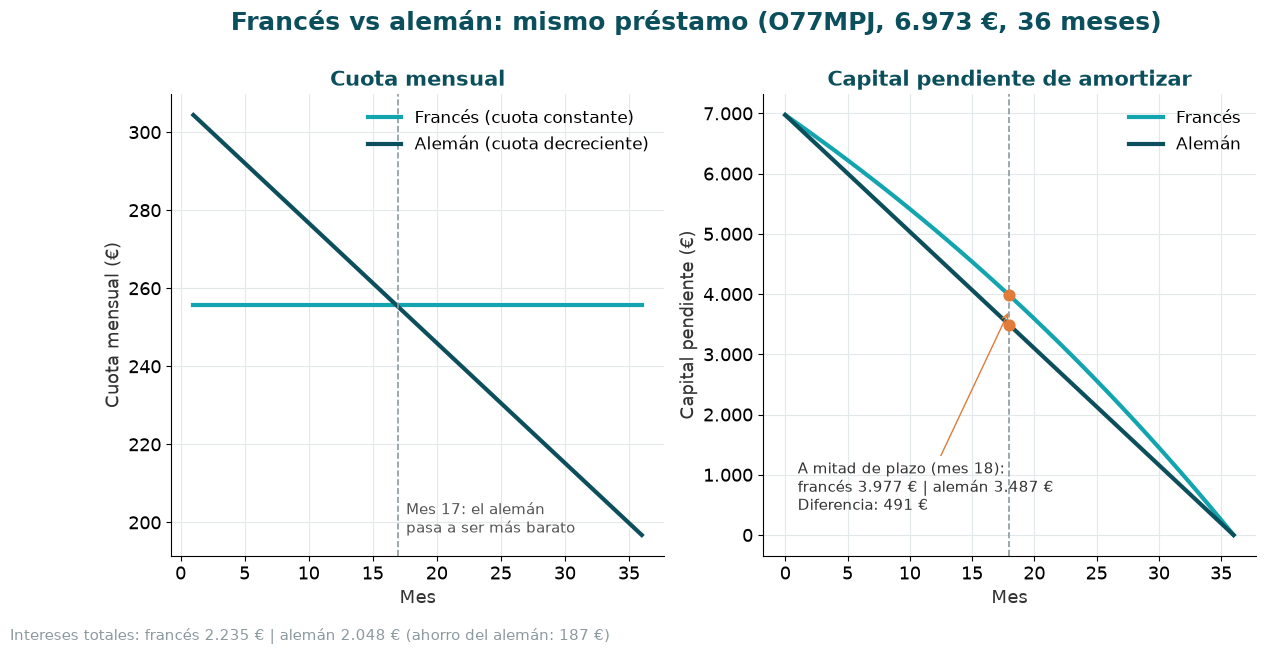

In [52]:
def grafico_frances_vs_aleman(id_prestamo=None):
    """GRÁFICO 3 (Punto 3): cuota y capital pendiente, francés vs alemán, para un préstamo.
    Usa datos, cuadros_frances y cuadros_aleman. Por defecto, el primer préstamo (datos.loc[0, 'ID'])."""
    id_ej = datos.loc[0, "ID"] if id_prestamo is None else id_prestamo
    cap_ej = datos.loc[datos["ID"] == id_ej, "capital_prestado"].iloc[0]
    fr_ej, al_ej = cuadros_frances[id_ej], cuadros_aleman[id_ej]
    n_ej = len(fr_ej); mitad = n_ej // 2
    cruce = al_ej.loc[al_ej["Cuota"] < fr_ej["Cuota"], "Periodo"].min()
    saldo_fr = fr_ej.loc[fr_ej["Periodo"] == mitad, "Saldo_Pendiente"].iloc[0]
    saldo_al = al_ej.loc[al_ej["Periodo"] == mitad, "Saldo_Pendiente"].iloc[0]
    int_fr, int_al = fr_ej["Intereses"].sum(), al_ej["Intereses"].sum()

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6))
    a1.plot(fr_ej["Periodo"], fr_ej["Cuota"], color=C_TURQ, lw=3, label="Francés (cuota constante)")
    a1.plot(al_ej["Periodo"], al_ej["Cuota"], color=C_OSCURO, lw=3, label="Alemán (cuota decreciente)")
    if pd.notna(cruce):
        a1.axvline(cruce, color=C_GRIS, ls="--", lw=1.2)
        y0, y1 = a1.get_ylim()
        a1.text(cruce + 0.6, y0 + (y1 - y0) * 0.04, f"Mes {int(cruce)}: el alemán\npasa a ser más barato",
                fontsize=10.5, va="bottom", color="#555555")
    a1.set_xlabel("Mes"); a1.set_ylabel("Cuota mensual (€)"); a1.set_title("Cuota mensual", fontsize=15)
    a1.yaxis.set_major_formatter(eje()); a1.legend(loc="upper right")

    a2.plot([0] + fr_ej["Periodo"].tolist(), [cap_ej] + fr_ej["Saldo_Pendiente"].tolist(), color=C_TURQ, lw=3, label="Francés")
    a2.plot([0] + al_ej["Periodo"].tolist(), [cap_ej] + al_ej["Saldo_Pendiente"].tolist(), color=C_OSCURO, lw=3, label="Alemán")
    a2.axvline(mitad, color=C_GRIS, ls="--", lw=1.2)
    a2.scatter([mitad, mitad], [saldo_fr, saldo_al], color=C_ALERTA, zorder=5, s=60)
    a2.annotate(f"A mitad de plazo (mes {mitad}):\nfrancés {fmt_num(saldo_fr)} € | alemán {fmt_num(saldo_al)} €\nDiferencia: {fmt_num(saldo_fr - saldo_al)} €",
                xy=(mitad, (saldo_fr + saldo_al) / 2), xytext=(1, cap_ej * 0.06), fontsize=10.5,
                arrowprops=dict(arrowstyle="->", color=C_ALERTA), color="#333333")
    a2.set_xlabel("Mes"); a2.set_ylabel("Capital pendiente (€)"); a2.set_title("Capital pendiente de amortizar", fontsize=15)
    a2.yaxis.set_major_formatter(eje()); a2.legend(loc="upper right")
    fig.suptitle(f"Francés vs alemán: mismo préstamo ({id_ej}, {fmt_num(cap_ej)} €, {n_ej} meses)",
                 fontsize=18, fontweight="bold", color=C_OSCURO, y=1.02)
    fig.text(0.01, -0.03, f"Intereses totales: francés {fmt_num(int_fr)} € | alemán {fmt_num(int_al)} € "
                          f"(ahorro del alemán: {fmt_num(int_fr - int_al)} €)", fontsize=11, color=C_GRIS)
    guardar(fig, "g3_frances_vs_aleman_ejemplo"); plt.show()

grafico_frances_vs_aleman()

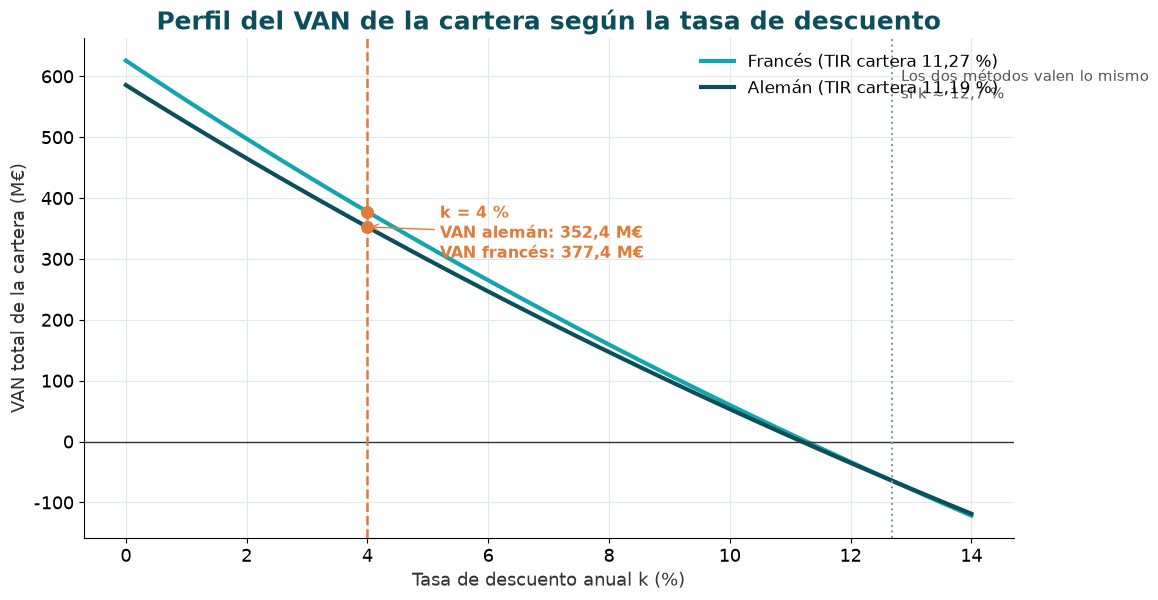

VAN cartera a k = 4%: alemán 352,433,253 € | francés 377,416,519 €
TIR de la cartera: alemán 11.19 % | francés 11.27 %
VAN total en tu notebook (viabilidad['VAN'].sum()): 372,544,896 €  <- debe parecerse al alemán


In [51]:
def grafico_perfil_van_cartera():
    """GRÁFICO 4 (Punto 4): perfil del VAN de la cartera según k, con método alemán y con francés. Usa datos."""
    K_REF = _k_referencia()
    d = datos[["capital_prestado", "interes_anual", "num_meses"]].astype(float)
    n_max = int(d["num_meses"].max())
    f_fr, f_al = np.zeros(n_max + 1), np.zeros(n_max + 1)       # cuotas totales de la cartera por mes
    for n, g in d.groupby("num_meses"):
        n = int(n); C = g["capital_prestado"].to_numpy(); i = g["interes_anual"].to_numpy() / 100 / 12
        tt = np.arange(1, n + 1)
        f_fr[1:n + 1] += (C * i / (1 - (1 + i) ** (-n))).sum()                      # francés: cuota constante
        A = C / n
        f_al[1:n + 1] += A.sum() + ((C[:, None] - (tt - 1)[None, :] * A[:, None]) * i[:, None]).sum(axis=0)  # alemán
    cap_total = d["capital_prestado"].sum()
    meses = np.arange(n_max + 1)

    def van_cartera(k, flujos):                                  # VAN = -A + sum(Qt/(1+r)^t), r mensual equivalente
        r_m = (1 + k) ** (1 / 12) - 1
        return -cap_total + (flujos[1:] / (1 + r_m) ** meses[1:]).sum()

    def tir_cartera(flujos):                                     # aproximaciones sucesivas (bisección)
        lo, hi = 0.0, 1.0
        for _ in range(100):
            m_ = (lo + hi) / 2
            if van_cartera((1 + m_) ** 12 - 1, flujos) > 0: lo = m_
            else: hi = m_
        return (1 + m_) ** 12 - 1

    ks = np.linspace(0, 0.14, 57)
    v_fr = np.array([van_cartera(k, f_fr) for k in ks]); v_al = np.array([van_cartera(k, f_al) for k in ks])
    tir_fr, tir_al = tir_cartera(f_fr), tir_cartera(f_al)
    van_fr, van_al = van_cartera(K_REF, f_fr), van_cartera(K_REF, f_al)

    fig, ax = plt.subplots()
    ax.plot(ks * 100, v_fr, color=C_TURQ, lw=3, label=f"Francés (TIR cartera {fmt_num(tir_fr * 100, 2)} %)")
    ax.plot(ks * 100, v_al, color=C_OSCURO, lw=3, label=f"Alemán (TIR cartera {fmt_num(tir_al * 100, 2)} %)")
    ax.axhline(0, color="#333333", lw=1); ax.axvline(K_REF * 100, color=C_ALERTA, ls="--", lw=1.8)
    ax.scatter([K_REF * 100] * 2, [van_fr, van_al], color=C_ALERTA, zorder=5, s=70)
    ax.annotate(f"k = {fmt_num(K_REF * 100, 0)} %\nVAN alemán: {fmt_num(van_al / 1e6, 1)} M€\nVAN francés: {fmt_num(van_fr / 1e6, 1)} M€",
                xy=(K_REF * 100, van_al), xytext=(K_REF * 100 + 1.2, van_fr * 0.8), fontsize=11.5,
                color=C_ALERTA, fontweight="bold", arrowprops=dict(arrowstyle="->", color=C_ALERTA))
    dif = v_fr - v_al                                            # ¿se cruzan las curvas? (equivale al punto de Fisher)
    sg = np.where(np.diff(np.sign(dif)) != 0)[0]
    if len(sg):
        j = sg[0]; kx = ks[j] - dif[j] * (ks[j + 1] - ks[j]) / (dif[j + 1] - dif[j])
        ax.axvline(kx * 100, color=C_GRIS, ls=":", lw=1.5)
        ax.text(kx * 100 + 0.15, ax.get_ylim()[1] * 0.85, f"Los dos métodos valen lo mismo\nsi k ≈ {fmt_num(kx * 100, 1)} %",
                fontsize=10.5, color="#555555")
    ax.yaxis.set_major_formatter(eje(1e6, "")); ax.set_ylabel("VAN total de la cartera (M€)")
    ax.set_xlabel("Tasa de descuento anual k (%)")
    ax.set_title("Perfil del VAN de la cartera según la tasa de descuento")
    ax.legend(loc="upper right")
    guardar(fig, "g4_perfil_van_cartera"); plt.show()
    print(f"VAN cartera a k = {K_REF:.0%}: alemán {van_al:,.0f} € | francés {van_fr:,.0f} €")
    print(f"TIR de la cartera: alemán {tir_al * 100:.2f} % | francés {tir_fr * 100:.2f} %")
    if "viabilidad" in globals():
        print(f"VAN total en tu notebook (viabilidad['VAN'].sum()): {viabilidad['VAN'].sum():,.0f} €  <- debe parecerse al alemán")

grafico_perfil_van_cartera()